# State-Dependent Kyle's Lambda and Execution Scheduling

**MSCF 46982 Market Microstructure and Algorithmic Trading — Final Paper**

Can the price impact of order flow (Kyle's $\lambda$) be forecast from the market's state one minute earlier, and does scheduling a large order around that forecast lower execution cost?

The notebook builds the data panel in q, tests three hypotheses about Kyle's $\lambda$, compares an interpretable and a machine-learning impact model out of sample, and evaluates the forecasts in an execution backtest.

| Section | Content |
|---|---|
| 0 | Setup and parameters |
| 1 | Server-side bucketing in q |
| 2 | Load the bucket panel (cached) |
| 3 | Sample periods and summary statistics (Table 1) |
| 4 | Intraday profiles (Figure 1) |
| 5 | Features: lagged state, expected and surprise flow |
| 6 | Questions 1–3: what moves impact (Table 2) |
| 7 | Question 4: forecasting impact out of sample (Table 3) |
| 8 | Reading λ from each model (Figures 2 and 3) |
| 9 | Question 5a: timing an order (Table 4) |
| 10 | Question 5b: pre-trade cost estimates (Table 5, Figure 4) |
| 11 | Summary |

## 0. Setup

**Packages** beyond the course environment (`pykx`, `pandas`, `numpy`, `matplotlib`, `keyring`): `pyarrow` (parquet cache), `statsmodels`, `scikit-learn`, `lightgbm`, `shap` and `scipy`. Local modules: `taq_data.py` (server access and cache), `features.py`, `models.py` and `execution.py`.

**Runtime.** With the parquet cache in `data/buckets/`, this section runs offline in seconds. Set `REQUERY = True` to rebuild the cache from the server: about 7 seconds per day, roughly 2.5 minutes for all 19 days.

**Trade conditions.** We keep regular trades (`" "`, `@`), automatic executions (`E`), intermarket sweeps (`F`) and odd lots (`I`). This drops late reports, out-of-sequence prints, derivatively priced trades and extended-hours prints.

In [1]:
import datetime as dt
import os
import ssl
from pathlib import Path

# q initialises TLS when pykx is imported and reads its CA bundle from this
# variable, so it must be set before the pykx import below.
# Some Python builds (e.g. on Windows) report no CA file; the cached data then needs no TLS.
ca_file = ssl.get_default_verify_paths().cafile
if ca_file:
    os.environ.setdefault("SSL_CA_CERT_FILE", ca_file)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pykx as kx
import shap
import statsmodels.api as sm
from IPython.display import display

import execution as E
import features as F
import models as M
import taq_data

plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "legend.fontsize": 9})
Path("figures").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

kx.q("\\l taq_buckets.q")

REQUERY = False
CACHE_DIR = Path("data/buckets")

SYMS = ["MMM", "AXP", "AAPL", "BA", "CAT", "CVX", "CSCO", "KO", "DIS", "DOW",
        "XOM", "GS", "HD", "IBM", "INTC", "JNJ", "JPM", "MCD", "MRK", "MSFT",
        "NKE", "PFE", "PG", "TRV", "UTX", "UNH", "VZ", "V", "WMT", "WBA"]
CONDS = " @EFI"
WIDTH = dt.timedelta(minutes=1)

# All 19 trading days on the server: February 2020, excluding Presidents' Day (Feb 17).
DATES = [d.date() for d in pd.bdate_range("2020-02-03", "2020-02-28") if d != pd.Timestamp("2020-02-17")]

# Training (with time-series CV inside) and a hold-out test that is touched once.
PERIODS = {
    "train": (dt.date(2020, 2, 3), dt.date(2020, 2, 14)),
    "test": (dt.date(2020, 2, 18), dt.date(2020, 2, 28)),
}

# Reporting subsamples: the test period splits into a calm week and the sell-off week.
SUBSAMPLES = {
    "train": (dt.date(2020, 2, 3), dt.date(2020, 2, 14)),
    "test: calm": (dt.date(2020, 2, 18), dt.date(2020, 2, 21)),
    "test: sell-off": (dt.date(2020, 2, 24), dt.date(2020, 2, 28)),
}


Welcome to KDB-X Community Edition!
For Community support, please visit https://kx.com/slack
Tutorials can be found at https://github.com/KxSystems/tutorials
Ready to go beyond the Community Edition? Email preview@kx.com



/Users/samaypanwar/Library/Caches/pypoetry/virtualenvs/microstructure-2xUXWsps-py3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Server-side bucketing in q

All aggregation runs on the kdb+ server: `bucketquery` (in `taq_buckets.q`) is sent over IPC as one self-contained lambda and returns a 30-stock × 390-minute table per day. A day of NBBO updates for 30 Dow stocks has millions of rows, but only 11,700 rows come back.

For stock $i$ and one-minute bucket $t$ the query computes:

**Trade signing (Lee and Ready, 1991).** Each trade $k$ is matched to the prevailing NBBO with an as-of join (`aj`), and $m_k = (b_k + a_k)/2$:
$$s_k = \begin{cases} +1 & p_k > m_k \\ -1 & p_k < m_k \\ \operatorname{sign}(p_k - p_{k'}) & p_k = m_k \text{ (tick rule, last non-zero change)} \end{cases}$$

**Signed flow and volume.** $\;\text{sflow}_t = \sum_{k \in t} s_k q_k, \qquad \text{vol}_t = \sum_{k \in t} q_k$

**Mid return in basis points.** With $mb_t$ the prevailing mid at the start of bucket $t$:
$$\Delta m_t = 10^4 \, \frac{mb_{t+1} - mb_t}{mb_t}$$

**Time-weighted spread and depth.** The NBBO is sampled on a 1-second grid $\{\tau\}$ inside the bucket:
$$\text{spr}_t = \frac{1}{60}\sum_{\tau \in t} \frac{a_\tau - b_\tau}{m_\tau}, \qquad \text{dep}_t = \frac{1}{60}\sum_{\tau \in t} \left(q^b_\tau + q^a_\tau\right)$$

**Order-flow imbalance (Cont, Kukanov and Stoikov, 2014).** For each NBBO update $n$:
$$e_n = \mathbb{1}\{b_n \ge b_{n-1}\} q^b_n - \mathbb{1}\{b_n \le b_{n-1}\} q^b_{n-1} - \mathbb{1}\{a_n \le a_{n-1}\} q^a_n + \mathbb{1}\{a_n \ge a_{n-1}\} q^a_{n-1}, \qquad \text{OFI}_t = \sum_{n \in t} e_n$$

**Realized variance.** From 10-second log mid returns $r_j$: $\;\text{rv1}_t = \sum_{j \in t} r_j^2, \qquad \text{rv5}_t = \sum_{s=t-4}^{t} \text{rv1}_s$

**Activity.** $\text{ntrd}_t$ = trade count and $\text{nq}_t$ = NBBO update count (a proxy for limit-order churn, since Level 1 data has no individual orders).

Quote sizes on this server are in round lots of 100 shares. `test_taq_buckets.py` checks every column against an independent pandas implementation on synthetic data.

In [2]:
print(Path("taq_buckets.q").read_text())

/ Server-side bucketing of NYSE TAQ for the state-dependent Kyle's lambda study.
/ .
/ bucketquery is fully self-contained (no globals), so the whole lambda can be
/ sent to the TAQ server over IPC and only the per-minute table comes back.
/ .
/ Output: one row per (sym, bucket) for 09:30 to 15:59, with
/   mb      mid at the start of the bucket
/   dm      mid change over the bucket, in bps: 1e4*(mb[t+1]-mb[t])%mb[t]
/   sflow   Lee-Ready signed volume (shares)
/   vol     total volume (shares)
/   ntrd    trade count
/   spr     time-weighted relative spread (ask-bid)%mid, 1-second sampling
/   dep     time-weighted quoted depth bsize+asize, 1-second sampling (round lots on the course server)
/   nq      number of NBBO updates
/   ofi     Cont-Kukanov-Stoikov order-flow imbalance (round lots on the course server)
/   rv1     realized variance of 10-second log mid returns within the bucket
/   rv5     rv1 summed over the last 5 buckets (including this one)
/ .
/ Every column describes

## 2. Load the bucket panel

`load_buckets` reads one parquet file per day and queries the server only for missing days.

In [3]:
panel = taq_data.load_buckets(DATES, SYMS, CONDS, WIDTH, CACHE_DIR, requery=REQUERY)

# Map each trading date to the name of the span that contains it.
def label_dates(spans: dict[str, tuple[dt.date, dt.date]]) -> dict[dt.date, str]:
    return {d: name for name, (lo, hi) in spans.items() for d in DATES if lo <= d <= hi}


panel["period"] = panel["date"].dt.date.map(label_dates(PERIODS))
panel["subsample"] = panel["date"].dt.date.map(label_dates(SUBSAMPLES))
panel["minute"] = (panel["bucket"] - pd.Timedelta("09:30:00")) // pd.Timedelta("1min")

print(f"{len(panel):,} rows = {panel['date'].nunique()} days x {panel['sym'].nunique()} stocks x "
      f"{panel['minute'].nunique()} minutes")
panel.head()

222,300 rows = 19 days x 30 stocks x 390 minutes


,date,sym,bucket,mb,dm,spr,dep,rv1,sflow,vol,ntrd,nq,ofi,rv5,period,subsample,minute
0,2020-02-03,AAPL,0 days 09:30:00,304.225,-25.967623,0.000468,12.883333,0.000023,-125994,1195518,12247,12806,-439.0,0.000023,train,train,0
1,2020-02-03,AAPL,0 days 09:31:00,303.435,20.267932,0.000402,8.466667,0.000020,-23073,520631,5446,10555,969.0,0.000043,train,train,1
2,2020-02-03,AAPL,0 days 09:32:00,304.050,29.600395,0.000272,9.716667,0.000002,92215,477357,4875,8818,1475.0,0.000045,train,train,2
3,2020-02-03,AAPL,0 days 09:33:00,304.950,24.430234,0.000244,10.566667,0.000004,23969,472613,4215,6586,308.0,0.000049,train,train,3
4,2020-02-03,AAPL,0 days 09:34:00,305.695,26.169875,0.000153,11.100000,0.000002,-23055,381151,4143,6653,831.0,0.000051,train,train,4


## 3. Sample periods and Table 1

The server holds February 2020 only. We split it in time order so every evaluation sample comes after its training sample:

| Period | Dates | Days | Use |
|---|---|---|---|
| Train | Feb 3 – Feb 14 | 10 | Estimation, with `TimeSeriesSplit` cross-validation by day |
| Test | Feb 18 – Feb 28 | 9 | Hold-out, touched once |

Nine test days give enough stock-days for forecast and execution comparisons. Results are also reported separately for the calm week (Feb 18–21) and the sell-off week (Feb 24–28, the start of the COVID-19 sell-off), which tests whether the impact model holds when the regime shifts.

Table 1 averages stock-day statistics within each subsample. Spread is in basis points; $\sigma(\Delta m)$ is the standard deviation of 1-minute mid returns.

In [4]:
daily = panel.groupby(["subsample", "date", "sym"]).agg(
    volume=("vol", "sum"),
    trades=("ntrd", "sum"),
    quotes=("nq", "sum"),
    spread_bps=("spr", lambda s: 1e4 * s.mean()),
    depth_lots=("dep", "mean"),
    sd_dm_bps=("dm", "std"),
    net_flow=("sflow", "sum"),
)
daily["abs_imbalance"] = daily["net_flow"].abs() / daily["volume"]

table1 = daily.groupby("subsample").agg(
    days=("volume", lambda s: s.index.get_level_values("date").nunique()),
    volume_m=("volume", lambda s: s.mean() / 1e6),
    trades_k=("trades", lambda s: s.mean() / 1e3),
    quotes_k=("quotes", lambda s: s.mean() / 1e3),
    spread_bps=("spread_bps", "mean"),
    depth_lots=("depth_lots", "mean"),
    sd_dm_bps=("sd_dm_bps", "mean"),
    abs_imbalance=("abs_imbalance", "mean"),
).reindex(list(SUBSAMPLES))

table1.columns = ["Days", "Volume (M sh)", "Trades (k)", "NBBO updates (k)", "Spread (bps)",
                  "Depth (lots)", "σ(Δm) 1-min (bps)", "|Net flow| / volume"]
table1.index.name = "Subsample (per stock-day means)"
table1.round(2).astype({"Days": int})

,Days,Volume (M sh),Trades (k),NBBO updates (k),Spread (bps),Depth (lots),σ(Δm) 1-min (bps),|Net flow| / volume
Subsample (per stock-day means),,,,,,,,
train,10,7.66,71.07,508.20,2.19,35.06,5.14,0.05
test: calm,4,7.20,67.45,507.93,2.31,35.32,5.13,0.05
test: sell-off,5,16.80,164.01,1196.52,3.81,22.19,12.48,0.05


## 4. Intraday profiles

Kyle's $\lambda = \sigma_v / 2\sigma_u$ predicts higher impact when information is high relative to noise trading. The intraday shape of volume, spreads and volatility is the first piece of evidence: each series is averaged by minute of day across stocks and days.

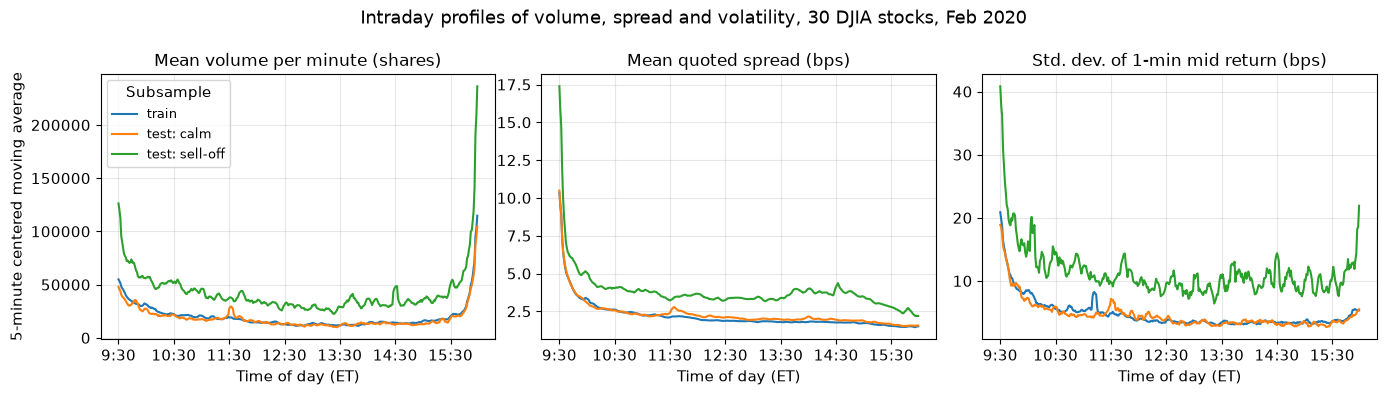

In [5]:
profile = panel.groupby(["subsample", "minute"]).agg(
    volume=("vol", "mean"),
    spread_bps=("spr", lambda s: 1e4 * s.mean()),
    sd_dm=("dm", "std"),
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
panels = [("volume", "Mean volume per minute (shares)"),
          ("spread_bps", "Mean quoted spread (bps)"),
          ("sd_dm", "Std. dev. of 1-min mid return (bps)")]
for ax, (col, title) in zip(axes, panels):
    for name in SUBSAMPLES:
        sub = profile[profile["subsample"] == name]
        ax.plot(sub["minute"], sub[col].rolling(5, center=True, min_periods=1).mean(), label=name)
    ax.set_title(title)
    ax.set_xlabel("Time of day (ET)")
    ax.set_xticks(range(0, 391, 60), [f"{9 + (30 + m) // 60}:{(30 + m) % 60:02d}" for m in range(0, 391, 60)])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("5-minute centered moving average")
axes[0].legend(title="Subsample")
fig.tight_layout()
fig.savefig("figures/fig1_intraday.pdf", bbox_inches="tight")
fig.suptitle("Intraday profiles of volume, spread and volatility, 30 DJIA stocks, Feb 2020")
fig.tight_layout()
plt.show()

## 5. Features

All quantities are for stock $i$ and bucket $t$; every normaliser is estimated on **training days only**.

| Symbol | Definition |
|---|---|
| $\Delta m_t$ | mid return in bps, winsorised at the training 0.1% / 99.9% quantiles |
| $x_t$ | $\text{sflow}_t / \bar V_i$, with $\bar V_i$ the training mean one-minute volume (same winsorisation) |
| $\text{spr}_{t-1}$ | $\log$ of the time-weighted spread in bps |
| $\text{rv}_{t-1}$ | $\log \text{rv5}$, realized variance over the last 5 minutes |
| $\text{dep}_{t-1}$ | $\log$ time-weighted quoted depth |
| $\text{act}_{t-1}$ | $\log(1 + \text{ntrd})$, trading activity (noise-trading proxy) |
| $\text{qupd}_{t-1}$ | $\log(1 + \text{nq})$, NBBO update count (limit-order churn proxy) |
| $\text{OFI}_{t-1}$ | order-flow imbalance divided by the stock's training mean depth |

State variables are **lagged one bucket within each stock-day** (the first bucket of each day is dropped), standardised with training means and standard deviations, and capped at $\pm 5$ SD.

**Expected and surprise flow (Hasbrouck, 1991).** A pooled AR(5), fitted on training rows, splits flow into a forecast and a surprise:
$$x_t = a + \sum_{j=1}^{5} \phi_j x_{t-j} + u_t, \qquad \hat x_t = \hat a + \sum_{j} \hat\phi_j x_{t-j}, \qquad u_t = x_t - \hat x_t$$

In [6]:
norm = F.fit_normalisers(panel[panel["period"] == "train"])
feat = F.raw_features(panel, norm)
scale = F.fit_standardiser(feat[feat["period"] == "train"])
feat = F.standardise(feat, scale)
ar_coef = F.fit_ar(feat[feat["period"] == "train"])
feat = F.add_surprise(feat, ar_coef)

train = feat[feat["period"] == "train"].copy()
test = feat[feat["period"] == "test"].copy()

print("AR(5) coefficients [a, phi_1..phi_5]:", ar_coef.round(3))
print(f"Training rows: {len(train):,}   test rows: {len(test):,}")
print(f"Share of flow variance that is predictable: {train['x_hat'].var() / train['x'].var():.1%}")

AR(5) coefficients [a, phi_1..phi_5]: [-0.02   0.062  0.052  0.035  0.028  0.04 ]
Training rows: 116,700   test rows: 105,030
Share of flow variance that is predictable: 1.1%


## 6. Questions 1–3: what moves impact (training sample)

Standard errors are clustered two ways, by stock and by date.

**Question 1 — Does order flow that could have been predicted still move prices?** Prediction: only the surprise does.
$$\Delta m_t = \mu + \lambda_e \hat x_t + \lambda_u u_t + \varepsilon_t, \qquad H_0: \lambda_u = \lambda_e$$

**Question 2 — Is impact highest at the open?** One slope per half-hour window $k$:
$$\Delta m_t = \mu + \sum_{k=0}^{12} \lambda_k \mathbb{1}\{t \in k\}\, x_t + \varepsilon_t, \qquad H_0: \lambda_0 = \dots = \lambda_{12}$$

**Question 3 — Do wide spreads and thin order books raise impact?** Kyle's $\lambda = \sigma_v / 2\sigma_u$ predicts a higher slope when information is high relative to noise:
$$\Delta m_t = \mu + \gamma' z_{t-1} + \Big(\lambda_0 + \sum_k \lambda_k z_{k,t-1}\Big) x_t + \varepsilon_t$$
Predicted signs: spread and volatility $+$ (information), depth $-$; activity is ambiguous (noise lowers $\lambda$, informed activity raises it).

In [7]:
m0 = M.clustered_ols(train["dm"], train[["x"]], train)
h1 = M.clustered_ols(train["dm"], train[["x_hat", "u"]], train)
h3_design = train[["x", *F.STATE_COLS]].assign(**{f"x*{c}": train["x"] * train[c] for c in F.STATE_COLS})
h3 = M.clustered_ols(train["dm"], h3_design, train)

window_x = pd.DataFrame({f"w{k}": (train["window"] == k) * train["x"] for k in range(F.N_WINDOWS)})
h2 = M.clustered_ols(train["dm"], window_x, train)
h2_f = h2.f_test(", ".join(f"w{k} = w0" for k in range(1, F.N_WINDOWS)))
h1_wald = h1.t_test("u - x_hat = 0")

def coef_column(res):
    return {k: f"{res.params[k]:.3f} ({res.tvalues[k]:.1f})" for k in res.params.index}

order = ["const", "x", "x_hat", "u", *F.STATE_COLS, *[f"x*{c}" for c in F.STATE_COLS]]
table2 = pd.DataFrame({"Constant impact": coef_column(m0), "Q1: surprise split": coef_column(h1), "Q3: market conditions": coef_column(h3)}).reindex(order).fillna("")
table2.loc["R²"] = [f"{r.rsquared:.3f}" for r in (m0, h1, h3)]
table2.index.name = "Coefficient (t-stat)"
display(table2)

print(f"Q1 Wald test lambda_u - lambda_e = {h1_wald.effect[0]:.2f}, p = {float(h1_wald.pvalue):.2g}")
print(f"Q2 F-test of equal window slopes: F = {float(h2_f.fvalue):.2f}, p = {float(h2_f.pvalue):.3g}")
print("Q2 window slopes:", h2.params.filter(like="w").round(2).to_dict())
table2.to_csv("outputs/table2_regressions.csv")

,Constant impact,Q1: surprise split,Q3: market conditions
Coefficient (t-stat),,,
const,0.112 (3.8),0.004 (0.1),0.100 (3.3)
x,3.807 (13.2),,3.375 (14.7)
x_hat,,-0.409 (-0.5),
u,,3.855 (13.1),
spr,,,0.054 (1.1)
rv,,,0.001 (0.0)
dep,,,-0.005 (-0.2)
act,,,0.101 (2.2)
qupd,,,-0.028 (-0.7)


Q1 Wald test lambda_u - lambda_e = 4.26, p = 1e-06
Q2 F-test of equal window slopes: F = 8.75, p = 0.00141
Q2 window slopes: {'w0': 6.07, 'w1': 4.41, 'w2': 3.69, 'w3': 3.55, 'w4': 3.6, 'w5': 2.95, 'w6': 4.07, 'w7': 2.76, 'w8': 3.37, 'w9': 3.52, 'w10': 3.35, 'w11': 3.22, 'w12': 2.84}


## 7. Question 4: can impact be forecast out of sample, and is machine learning worth it?

| Model (code name) | Specification | Why it is in the comparison |
|---|---|---|
| Constant impact (M0) | $\Delta m_t = \mu + \lambda x_t$ | Kyle benchmark |
| Condition-dependent impact (M1) | Question 3 regression plus window interactions $\lambda_w x_t$ | interpretable state-dependent $\lambda$ |
| + square-root term (M1c) | M1 $+\; c\,\operatorname{sign}(x_t)\sqrt{\lvert x_t\rvert}$ | tests whether concavity (the square-root law) explains the ML gain |
| Gradient boosting (M2) | LightGBM $f(x_t, z_{t-1}, \text{minute})$, monotone increasing in $x_t$ | flexible non-linear benchmark |

M2's hyperparameters are chosen by **`TimeSeriesSplit` over training days** (4 expanding folds, one-day gap); the test days are used once. Out-of-sample fit is $R^2 = 1 - \sum (\Delta m - \widehat{\Delta m})^2 / \sum (\Delta m - \overline{\Delta m})^2$ within each subsample.

**Diebold–Mariano test.** With squared-error losses $L^A, L^B$, the differential is averaged across stocks in each test minute, $d_t = \frac{1}{N}\sum_i (L^A_{it} - L^B_{it})$, and
$$DM = \bar d \,\big/\, \sqrt{\hat\sigma^2_{NW}(d)/T},$$
with a Newey–West variance (10 lags). Negative values favour model A.

In [8]:
m1 = M.clustered_ols(train["dm"], M.m1_design(train), train)
m1c = M.clustered_ols(train["dm"], M.m1_design(train, concave=True), train)
m2_best, m2_cv = M.tune_m2(train)
m2 = M.fit_m2(train, m2_best)
print("M2 hyperparameters chosen by time-series CV:", m2_best)
display(m2_cv.round(3).head(4))

def predict_all(d):
    return {
        "M0": m0.predict(sm.add_constant(d[["x"]], has_constant="add")),
        "M1": m1.predict(sm.add_constant(M.m1_design(d), has_constant="add")),
        "M1c": m1c.predict(sm.add_constant(M.m1_design(d, concave=True), has_constant="add")),
        "M2": m2.predict(d[M.M2_FEATURES]),
    }

def r2(y, p):
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()

preds = predict_all(test)
minute_key = test["date"].astype(str) + "-" + test["minute"].astype(str)
loss = {m: (test["dm"] - p) ** 2 for m, p in preds.items()}
rows = []
for m, p in preds.items():
    row = {"Model": m, "R² test": r2(test["dm"], p)}
    for s in ["test: calm", "test: sell-off"]:
        mask = test["subsample"] == s
        row[f"R² {s[6:]}"] = r2(test.loc[mask, "dm"], p[mask])
    if m != "M0":
        row["DM vs M0"], row["p vs M0"] = M.diebold_mariano(loss[m], loss["M0"], minute_key)
    rows.append(row)
table3 = pd.DataFrame(rows).set_index("Model")
dm_m2_m1c = M.diebold_mariano(loss["M2"], loss["M1c"], minute_key)
display(table3.round(4))
print(f"DM test M2 vs M1c: stat = {dm_m2_m1c[0]:.2f}, p = {dm_m2_m1c[1]:.2g}")
table3.to_csv("outputs/table3_forecasts.csv")

M2 hyperparameters chosen by time-series CV: {'num_leaves': 15, 'min_child_samples': 200, 'n_estimators': 200}


,num_leaves,min_child_samples,n_estimators,cv_mse
0,15,200,200,20.527
1,15,1000,200,20.586
2,31,1000,200,20.600
3,31,200,200,20.607


,R² test,R² calm,R² sell-off,DM vs M0,p vs M0
Model,,,,,
M0,0.0792,0.0949,0.0765,NaN,NaN
M1,0.0892,0.1084,0.0860,-4.4007,0.0
M1c,0.1271,0.1719,0.1200,-15.4924,0.0
M2,0.1366,0.1883,0.1286,-13.8391,0.0


DM test M2 vs M1c: stat = -4.46, p = 8.2e-06


## 8. Reading lambda from each model

Lambda is never observed bucket by bucket, so each model's $\hat\lambda_t$ is its slope in flow given the state:

- M1: $\hat\lambda_t = \hat\lambda_0 + \sum_k \hat\lambda_k z_{k,t-1} + \hat\lambda_{w(t)}$.
- M2: a symmetric finite difference around zero flow, with $\delta$ equal to the training standard deviation of $x$:
$$\hat\lambda_t = \frac{f(\delta, z_{t-1}) - f(-\delta, z_{t-1})}{2\delta}$$

**Figure 2** shows (a) the Question 2 window slopes and (b) the shape of impact in flow: the linear Kyle line (M0), the concave M1c fit and M2's partial dependence. **Figure 3** shows what drives M2 through SHAP values (Lundberg and Lee, 2017).

Correlation of M1 and M2 lambda on test rows: 0.82
                lam_M1  lam_M2
subsample                     
test: calm        3.61    6.71
test: sell-off    5.70   10.41


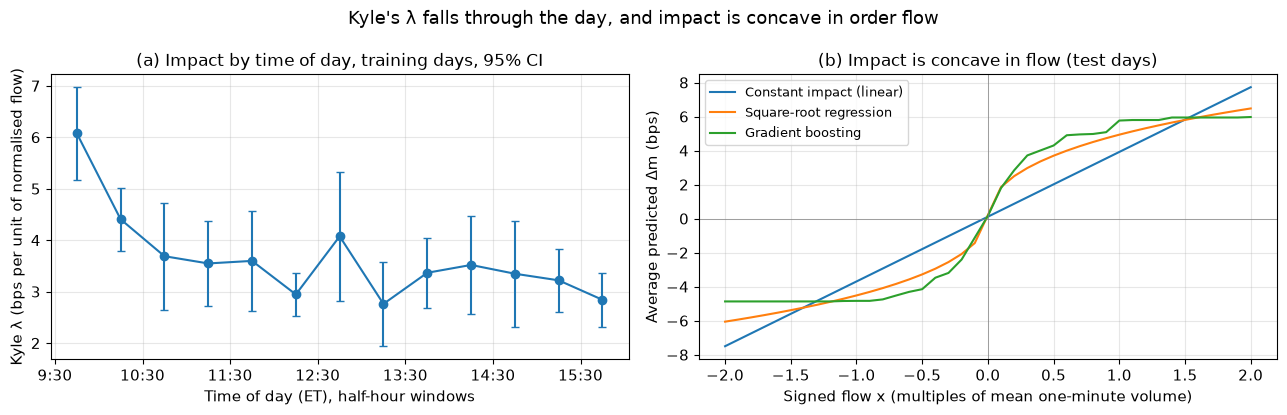

In [9]:
x_ref = train["x"].std()
for d in (train, test):
    d["lam_M1"] = M.lambda_m1(m1.params, d)
    d["lam_M2"] = M.lambda_m2(m2, d, x_ref)
print(f"Correlation of M1 and M2 lambda on test rows: {test[['lam_M1', 'lam_M2']].corr().iloc[0, 1]:.2f}")
print(test.groupby("subsample")[["lam_M1", "lam_M2"]].mean().round(2))

# Panel (a): Question 2 slopes with 95% CIs. Panel (b): average predicted dm as flow varies.
ci = h2.conf_int().filter(like="w", axis=0)
slopes = h2.params.filter(like="w")
centres = 30 * np.arange(F.N_WINDOWS) + 15
sample = test.sample(3000, random_state=0)
grid_x = np.linspace(-2, 2, 41)
curves = {"Constant impact (linear)": [], "Square-root regression": [], "Gradient boosting": []}
for gx in grid_x:
    s = sample.assign(x=gx)
    p = predict_all(s)
    curves["Constant impact (linear)"].append(p["M0"].mean())
    curves["Square-root regression"].append(p["M1c"].mean())
    curves["Gradient boosting"].append(p["M2"].mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.errorbar(centres, slopes, yerr=[slopes - ci[0], ci[1] - slopes], fmt="o-", capsize=3)
ax1.set_xticks(range(0, 391, 60), [f"{9 + (30 + m) // 60}:{(30 + m) % 60:02d}" for m in range(0, 391, 60)])
ax1.set_xlabel("Time of day (ET), half-hour windows")
ax1.set_ylabel("Kyle λ (bps per unit of normalised flow)")
ax1.set_title("(a) Impact by time of day, training days, 95% CI")
ax1.grid(alpha=0.3)
for name, ys in curves.items():
    ax2.plot(grid_x, ys, label=name)
ax2.axhline(0, color="grey", lw=0.5)
ax2.axvline(0, color="grey", lw=0.5)
ax2.set_xlabel("Signed flow x (multiples of mean one-minute volume)")
ax2.set_ylabel("Average predicted Δm (bps)")
ax2.set_title("(b) Impact is concave in flow (test days)")
ax2.legend()
ax2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/fig2_lambda_shape.pdf", bbox_inches="tight")
fig.suptitle("Kyle's λ falls through the day, and impact is concave in order flow")
fig.tight_layout()
plt.show()

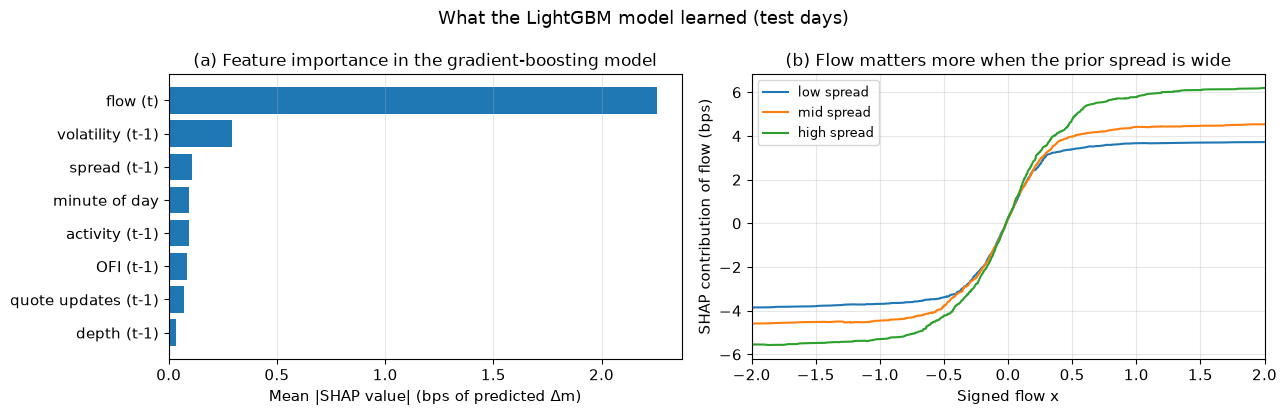

In [10]:
explainer = shap.TreeExplainer(m2)
shap_sample = test.sample(4000, random_state=1)[M.M2_FEATURES]
shap_values = explainer.shap_values(shap_sample)

labels = {"x": "flow (t)", "spr": "spread (t-1)", "rv": "volatility (t-1)", "dep": "depth (t-1)",
          "act": "activity (t-1)", "qupd": "quote updates (t-1)", "ofi": "OFI (t-1)", "minute": "minute of day"}
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=M.M2_FEATURES).sort_values()
x_shap = pd.Series(shap_values[:, 0])
interaction = pd.DataFrame({"spr": shap_sample["spr"].to_numpy(), "x": shap_sample["x"].to_numpy(), "shap_x": x_shap})
interaction["spread tercile"] = pd.qcut(interaction["spr"], 3, labels=["low spread", "mid spread", "high spread"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.barh([labels[c] for c in mean_abs.index], mean_abs.to_numpy())
ax1.set_xlabel("Mean |SHAP value| (bps of predicted Δm)")
ax1.set_title("(a) Feature importance in the gradient-boosting model")
ax1.grid(alpha=0.3, axis="x")
for name, grp in interaction.groupby("spread tercile", observed=True):
    grp = grp.sort_values("x")
    ax2.plot(grp["x"], grp["shap_x"].rolling(200, center=True, min_periods=50).mean(), label=name)
ax2.set_xlim(-2, 2)
ax2.set_xlabel("Signed flow x")
ax2.set_ylabel("SHAP contribution of flow (bps)")
ax2.set_title("(b) Flow matters more when the prior spread is wide")
ax2.legend()
ax2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/fig3_shap.pdf", bbox_inches="tight")
fig.suptitle("What the LightGBM model learned (test days)")
fig.tight_layout()
plt.show()

## 9. Question 5a: does timing an order around the λ forecast beat TWAP?

**Setup.** Buy $W$ units of the stock's mean one-minute volume over $N = 60$ one-minute buckets, starting at 10:00, 11:00, …, 15:00 on each test stock-day (1,620 orders). Buying $w_t$ moves the mid by $\lambda_t w_t$ bps; with fills spread through the bucket the average fill pays half of it. Implementation shortfall per share is
$$\mathrm{IS} = \frac{1}{W}\sum_{t} w_t\Big(\tfrac12 \lambda_t w_t + c \sum_{s<t}\lambda_s w_s\Big),$$
with $c = 0$ (one-minute impact is transient) or $c = 1$ (fully permanent).

**Optimal schedule.** Minimising $\sum_t \lambda_t w_t^2$ subject to $\sum_t w_t = W$ gives the Lagrangian condition $2\lambda_t w_t = \eta$, so
$$w_t^* = W \,\frac{\lambda_t^{-1}}{\sum_s \lambda_s^{-1}}.$$
With constant $\lambda$ this is TWAP. The adaptive strategies re-solve this each minute for the remaining quantity, using the state-based forecast for the next bucket. For later buckets the **naive** version assumes $\lambda$ returns to the training time-of-day profile $\bar\lambda$; the **persistence-aware** version lets the current deviation decay at the autocorrelation $\rho(k)$ measured on training days, $\hat\lambda_{t+k} = \bar\lambda_{t+k} + \rho(k)(\hat\lambda_t - \bar\lambda_t)$.

**Shrinkage.** Forecasts are shrunk towards the profile, $\tilde\lambda_t = \bar\lambda_{\tau(t)} + \alpha(\hat\lambda_t - \bar\lambda_{\tau(t)})$, with $\alpha$ chosen on **training days**.

**Evaluator.** Every strategy is scored with an ex-post $\lambda^{ev}_t = \sum_{s=t}^{t+20} x_s \Delta m_s / \sum_{s=t}^{t+20} x_s^2$ from the same stock-day. It uses only data from bucket $t$ onward, so it is independent of the information the schedules used, and no forecasting model grades itself.

**Market impact limitation.** Historical data cannot show how prices would have reacted to our extra flow; these costs are model-based counterfactuals.

In [11]:
ADV_SHARE = 0.05
W_ORDER = ADV_SHARE * 390          # W in units of mean one-minute volume (ADV = 390 x mean minute volume)
minute_idx = np.arange(390)
h2_slopes = h2.params.filter(like="w").to_numpy()
profiles = {"ToD": h2_slopes[np.minimum(minute_idx // 30, F.N_WINDOWS - 1)],
            "M1": E.profile_by_minute(train, "lam_M1"),
            "M2": E.profile_by_minute(train, "lam_M2")}

# Persistence of forecast deviations from the profile, measured on training days.
acfs = {m: E.deviation_acf(train, f"lam_{m}", profiles[m]) for m in ["M1", "M2"]}
print("Autocorrelation of λ deviations at lags 1, 5, 15, 30, 59 minutes:")
for m, a in acfs.items():
    print(f"  {m}:", a[[1, 5, 15, 30, 59]].round(2))

def build_grids(d, alpha):
    dm_grid, index = E.to_grid(d, "dm")
    x_grid, _ = E.to_grid(d, "x")
    grids = {"eval": E.evaluator_lambda(dm_grid, x_grid)}
    for m in ["M1", "M2"]:
        raw = E.to_grid(d, f"lam_{m}")[0]
        grids[m] = profiles[m][None, :] + alpha * (raw - profiles[m][None, :])
    return grids, index

def backtest(d, alpha):
    grids, index = build_grids(d, alpha)
    bt = E.run_backtest(grids, profiles, W_ORDER, acfs)
    bt["date"] = index.get_level_values("date")[bt["stockday"]]
    return bt

def cost_vs_twap(d, alpha):
    mean = backtest(d, alpha).groupby("strategy")["is_transient"].mean()
    return 100 * (mean / mean["TWAP"] - 1)

alphas = [0.0, 0.25, 0.5, 1.0]
alpha_table = pd.DataFrame({a: cost_vs_twap(train, a) for a in alphas}).T.drop(columns="TWAP")
alpha_table.index.name = "α (training days)"
display(alpha_table.round(2).rename(columns=lambda c: f"{c}: % cost vs TWAP"))
alpha_star = {m: float(alpha_table[f"{m} persistent"].idxmin()) for m in ["M1", "M2"]}
print("Shrinkage chosen on training days (persistence-aware schedules):", alpha_star)

Autocorrelation of λ deviations at lags 1, 5, 15, 30, 59 minutes:
  M1: [0.71 0.63 0.58 0.55 0.51]
  M2: [0.9  0.79 0.73 0.69 0.63]


strategy,M1: % cost vs TWAP,M1 persistent: % cost vs TWAP,M2: % cost vs TWAP,M2 persistent: % cost vs TWAP,ToD: % cost vs TWAP
α (training days),,,,,
0.00,1.00,1.00,0.36,0.36,0.41
0.25,1.31,1.03,0.91,0.38,0.41
0.50,2.48,1.25,2.42,0.43,0.41
1.00,9.80,3.13,8.15,0.57,0.41


Shrinkage chosen on training days (persistence-aware schedules): {'M1': 0.0, 'M2': 0.0}


In [12]:
def clustered_mean(series, dates):
    fit = sm.OLS(series.to_numpy(), np.ones(len(series))).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(dates)[0]})
    return fit.params[0], fit.tvalues[0]

full = backtest(test, 1.0)
tuned = {m: backtest(test, alpha_star[m]) for m in ["M1", "M2"]}
base = full[full["strategy"] == "TWAP"].set_index(["stockday", "start"])
calm = base["date"] <= pd.Timestamp("2020-02-21")

variants = [("TWAP", full, "TWAP"), ("Time of day", full, "ToD"),
            ("M1 naive, α = 1", full, "M1"), ("M2 naive, α = 1", full, "M2"),
            ("M1 persistence-aware, α = 1", full, "M1 persistent"),
            ("M2 persistence-aware, α = 1", full, "M2 persistent"),
            ("M1 persistence-aware, training α", tuned["M1"], "M1 persistent"),
            ("M2 persistence-aware, training α", tuned["M2"], "M2 persistent")]
rows = []
for label, bt, strategy in variants:
    g = bt[bt["strategy"] == strategy].set_index(["stockday", "start"]).loc[base.index]
    diff = g["is_transient"] - base["is_transient"]
    saving, t = clustered_mean(diff, base["date"]) if strategy != "TWAP" else (0.0, np.nan)
    rows.append({"Strategy": label,
                 "IS calm (bps)": g.loc[calm, "is_transient"].mean(),
                 "IS sell-off (bps)": g.loc[~calm, "is_transient"].mean(),
                 "IS all (bps)": g["is_transient"].mean(),
                 "Cost vs TWAP (%)": 100 * diff.mean() / base["is_transient"].mean(),
                 "t (date-clustered)": t,
                 "IS permanent (bps)": g["is_permanent"].mean()})
table4 = pd.DataFrame(rows).set_index("Strategy")
display(table4.round(3))
print("TWAP cost scales linearly with size: 1% / 5% / 10% of ADV =",
      [round(float(base["is_transient"].mean()) * s / ADV_SHARE, 2) for s in (0.01, 0.05, 0.10)], "bps")
table4.to_csv("outputs/table4_execution.csv")

# Dollar cost of a typical order: 5% of the average stock's daily dollar volume on training days.
daily_dollars = panel[panel["period"] == "train"].assign(dollars=lambda d: d["vol"] * d["mb"])
order_notional = ADV_SHARE * daily_dollars.groupby(["date", "sym"])["dollars"].sum().mean()
twap_bps = float(base["is_transient"].mean())
print(f"Average order notional at {ADV_SHARE:.0%} of ADV: ${order_notional / 1e6:.1f}M; "
      f"TWAP impact cost {twap_bps:.2f} bps = ${order_notional * twap_bps * 1e-4:,.0f}")

# Sanity check of the machinery: an oracle that schedules on the evaluator's own lambda.
oracle_grids, _ = build_grids(test, 1.0)
oracle_costs = []
for start in E.START_MINUTES:
    lam_eval = oracle_grids["eval"][:, start:start + E.HORIZON]
    ok = np.isfinite(lam_eval).all(axis=1)
    w_oracle = E.static_schedule(np.maximum(lam_eval[ok], 0.5), W_ORDER)
    oracle_costs.append(E.shortfall(w_oracle, lam_eval[ok], 0.0))
oracle_vs_twap = 100 * (np.concatenate(oracle_costs).mean() / base["is_transient"].mean() - 1)
print(f"Oracle schedule (evaluator lambda known, floored at 0.5): {oracle_vs_twap:.1f}% cost vs TWAP")

,IS calm (bps),IS sell-off (bps),IS all (bps),Cost vs TWAP (%),t (date-clustered),IS permanent (bps)
Strategy,,,,,,
TWAP,1.140,1.496,1.338,0.000,NaN,81.137
Time of day,1.148,1.501,1.344,0.450,4.092,80.985
"M1 naive, α = 1",1.257,2.433,1.910,42.782,2.615,80.616
"M2 naive, α = 1",1.259,3.113,2.289,71.078,2.398,81.071
"M1 persistence-aware, α = 1",1.169,1.547,1.379,3.057,4.290,80.890
"M2 persistence-aware, α = 1",1.147,1.521,1.355,1.241,4.035,81.162
"M1 persistence-aware, training α",1.152,1.508,1.350,0.871,3.541,80.863
"M2 persistence-aware, training α",1.144,1.503,1.343,0.407,2.289,81.226


TWAP cost scales linearly with size: 1% / 5% / 10% of ADV = [0.27, 1.34, 2.68] bps
Average order notional at 5% of ADV: $52.6M; TWAP impact cost 1.34 bps = $7,039


Oracle schedule (evaluator lambda known, floored at 0.5): -79.5% cost vs TWAP


## 10. Question 5b: does the forecast improve pre-trade cost estimates?

Timing exploits only *relative* differences in $\lambda$ within the hour. A persistent shift in $\lambda$ raises the cost of every bucket alike and leaves $w^*$ unchanged, but it still matters for **pre-trade cost estimates**, which drive order sizing, participation limits and the decision to trade now or defer.

For an order starting at $s$, each model forecasts the $\lambda$ path by letting the current deviation from its time-of-day profile decay at the autocorrelation $\rho(k)$ measured on training days:
$$\hat\lambda_{s+k} = \bar\lambda_{s+k} + \rho(k)\,\big(\hat\lambda_s - \bar\lambda_s\big), \qquad \widehat{\mathrm{IS}} = \kappa \cdot \tfrac12 \tfrac{W}{N} \cdot \tfrac{1}{N}\sum_k \hat\lambda_{s+k}$$
where the scale $\kappa$ is calibrated on training orders. Forecasts are compared with the realised TWAP cost under the evaluator. Two benchmarks ignore state: a single constant, and a per-stock constant (each stock's mean training cost), which captures what a desk already knows about which stocks are expensive. Paired tests of squared errors are clustered by date.

,RMSE (bps),MAE (bps),Bias (bps),Corr. with realised,Δ MSE vs Const,t vs Const,Δ MSE vs Stock,t vs Stock
Forecast,,,,,,,,
Const,1.086,0.692,0.260,NaN,NaN,NaN,NaN,NaN
Stock,0.887,0.582,0.260,0.623,-0.392,-5.885,NaN,NaN
ToD,1.089,0.694,0.260,0.014,0.008,1.318,0.401,5.710
M1,1.006,0.679,0.047,0.305,-0.167,-3.862,0.225,6.265
M2,0.966,0.670,0.014,0.401,-0.246,-4.056,0.147,5.862
Stock x M1,0.797,0.555,0.050,0.660,-0.543,-4.636,-0.150,-2.673
Stock x M2,0.833,0.581,0.010,0.616,-0.484,-4.259,-0.092,-1.726


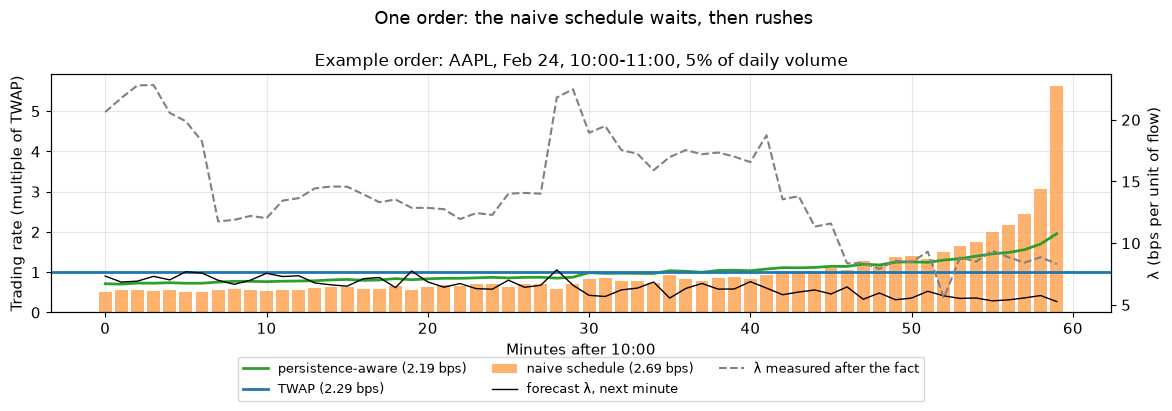

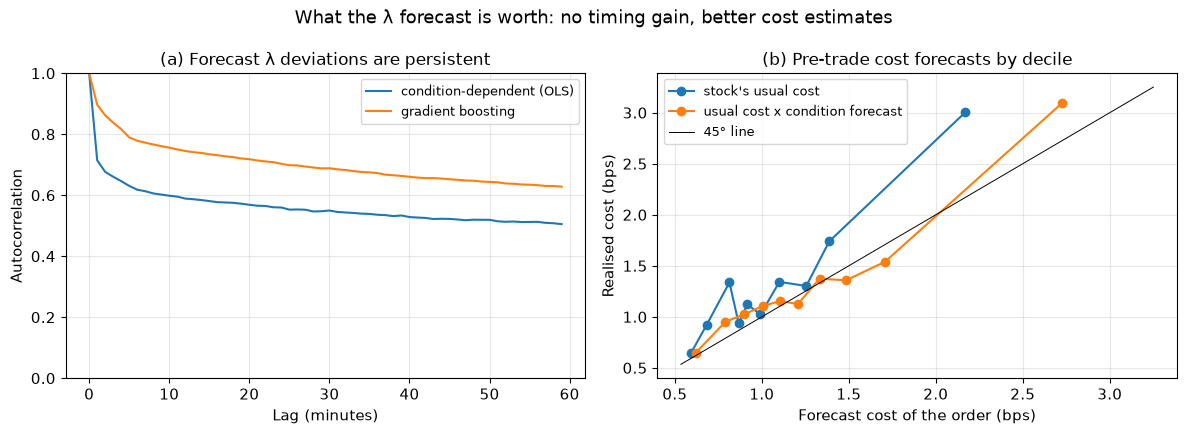

In [13]:
pre = {}
for name, d in [("train", train), ("test", test)]:
    grids, index = build_grids(d, 1.0)
    tbl = E.pretrade_forecasts(grids, profiles, acfs, W_ORDER)
    tbl["date"] = index.get_level_values("date")[tbl["stockday"]]
    tbl["sym"] = index.get_level_values("sym")[tbl["stockday"]]
    pre[name] = tbl

# Per-stock constant: each stock's mean realised cost on training orders (cross-sectional benchmark).
stock_cost = pre["train"].groupby("sym")["realized"].mean()
for tbl in pre.values():
    tbl["Stock"] = tbl["sym"].map(stock_cost)

# Stock x model: the stock's level, scaled by the model's forecast relative to its own
# training mean for that stock, so the state adds only time-series information.
for m in ["M1", "M2"]:
    model_level = pre["train"].groupby("sym")[m].mean()
    for tbl in pre.values():
        tbl[f"Stock x {m}"] = tbl["Stock"] * tbl[m] / tbl["sym"].map(model_level)

rows = []
forecasts = {}
for m in ["Const", "Stock", "ToD", "M1", "M2", "Stock x M1", "Stock x M2"]:
    kappa = pre["train"]["realized"].mean() / pre["train"][m].mean()
    fc = kappa * pre["test"][m]
    forecasts[m] = fc
    err = pre["test"]["realized"] - fc
    row = {"Forecast": m, "RMSE (bps)": np.sqrt((err ** 2).mean()), "MAE (bps)": err.abs().mean(),
           "Bias (bps)": err.mean(),
           "Corr. with realised": np.corrcoef(fc, pre["test"]["realized"])[0, 1] if fc.std() > 1e-9 else np.nan}
    for ref in ["Const", "Stock"]:
        if m in ("Const", "Stock") and ref != "Const" or m == ref:
            continue
        d_sq = err ** 2 - (pre["test"]["realized"] - forecasts[ref]) ** 2
        row[f"Δ MSE vs {ref}"], row[f"t vs {ref}"] = clustered_mean(d_sq, pre["test"]["date"])
    rows.append(row)
table5 = pd.DataFrame(rows).set_index("Forecast")
display(table5.round(3))
table5.to_csv("outputs/table5_pretrade.csv")

# Panel (a): one example order, AAPL on Feb 24 from 10:00, following the full M1 forecast.
example_grids, example_index = build_grids(test, 1.0)
row = list(example_index).index((pd.Timestamp("2020-02-24"), "AAPL"))
sl = slice(30, 30 + E.HORIZON)
ref = np.median(profiles["M1"])
lam_next = E.floor_lambda(np.nan_to_num(example_grids["M1"][row:row + 1, sl], nan=ref), ref)
w_forecast = E.adaptive_schedule(lam_next, E.floor_lambda(profiles["M1"][sl], ref), W_ORDER)[0]
w_persistent = E.adaptive_schedule(lam_next, E.floor_lambda(profiles["M1"][sl], ref), W_ORDER,
                                   acf=acfs["M1"], floor=E.LAMBDA_FLOOR_SHARE * ref)[0]
w_twap = np.full(E.HORIZON, W_ORDER / E.HORIZON)
lam_after = example_grids["eval"][row, sl]
cost = {name: E.shortfall(w[None, :], lam_after[None, :], 0.0)[0]
        for name, w in [("TWAP", w_twap), ("naive", w_forecast), ("persistent", w_persistent)]}

fig, ax0 = plt.subplots(figsize=(12, 4.2))
clock = np.arange(E.HORIZON)
ax0.bar(clock, w_forecast / w_twap, color="tab:orange", alpha=0.6, label=f"naive schedule ({cost['naive']:.2f} bps)")
ax0.plot(clock, w_persistent / w_twap, color="tab:green", lw=2, label=f"persistence-aware ({cost['persistent']:.2f} bps)")
ax0.axhline(1, color="tab:blue", lw=2, label=f"TWAP ({cost['TWAP']:.2f} bps)")
ax0.set_xlabel("Minutes after 10:00")
ax0.set_ylabel("Trading rate (multiple of TWAP)")
ax0.set_title("Example order: AAPL, Feb 24, 10:00-11:00, 5% of daily volume")
twin = ax0.twinx()
twin.plot(clock, lam_next[0], color="black", lw=1, label="forecast λ, next minute")
twin.plot(clock, lam_after, color="grey", lw=1.5, ls="--", label="λ measured after the fact")
twin.set_ylabel("λ (bps per unit of flow)")
handles = ax0.get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
ax0.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
ax0.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/fig4_example.pdf", bbox_inches="tight")
fig.suptitle("One order: the naive schedule waits, then rushes")
fig.tight_layout()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

names = {"M1": "condition-dependent (OLS)", "M2": "gradient boosting"}
for m, a in acfs.items():
    ax1.plot(np.arange(len(a)), a, label=names[m])
ax1.set_xlabel("Lag (minutes)")
ax1.set_ylabel("Autocorrelation")
ax1.set_title("(a) Forecast λ deviations are persistent")
ax1.set_ylim(0, 1)
ax1.legend()
ax1.grid(alpha=0.3)

lims = []
for name, label in [("Stock", "stock's usual cost"), ("Stock x M1", "usual cost x condition forecast")]:
    test_pre = pre["test"].assign(forecast=forecasts[name])
    test_pre["decile"] = pd.qcut(test_pre["forecast"], 10, labels=False, duplicates="drop")
    binned = test_pre.groupby("decile")[["forecast", "realized"]].mean()
    ax2.plot(binned["forecast"], binned["realized"], "o-", label=label)
    lims += [binned.min().min(), binned.max().max()]
lim = [min(lims) * 0.9, max(lims) * 1.05]
ax2.plot(lim, lim, color="black", lw=0.7, label="45° line")
ax2.set_xlabel("Forecast cost of the order (bps)")
ax2.set_ylabel("Realised cost (bps)")
ax2.set_title("(b) Pre-trade cost forecasts by decile")
ax2.legend()
ax2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/fig5_value.pdf", bbox_inches="tight")
fig.suptitle("What the λ forecast is worth: no timing gain, better cost estimates")
fig.tight_layout()
plt.show()

## 11. Summary

The cell below collects the headline numbers used in the report. Interpretation, limitations and extensions are in the PDF write-up.

In [14]:
summary = {
    "lambda_u (surprise flow)": round(float(h1.params["u"]), 2),
    "lambda_e (expected flow)": round(float(h1.params["x_hat"]), 2),
    "Q2 slope 09:30-10:00 / mean 12:00-14:00": (round(float(slopes["w0"]), 2),
                                                round(float(slopes[["w5", "w6", "w7", "w8"]].mean()), 2)),
    "x*spread (Q3)": round(float(h3.params["x*spr"]), 3),
    "x*depth (Q3)": round(float(h3.params["x*dep"]), 3),
    "OOS R2 M0 / M1 / M1c / M2": tuple(table3["R² test"].round(3)),
    "Timing: alpha chosen on training": {m: float(a) for m, a in alpha_star.items()},
    "Pre-trade RMSE Const / Stock / Stock x M1": tuple(round(float(table5.loc[k, "RMSE (bps)"]), 3)
                                                      for k in ["Const", "Stock", "Stock x M1"]),
}
for k, v in summary.items():
    print(f"{k:38s} {v}")

lambda_u (surprise flow)               3.85
lambda_e (expected flow)               -0.41
Q2 slope 09:30-10:00 / mean 12:00-14:00 (6.07, 3.29)
x*spread (Q3)                          0.866
x*depth (Q3)                           -0.616
OOS R2 M0 / M1 / M1c / M2              (0.079, 0.089, 0.127, 0.137)
Timing: alpha chosen on training       {'M1': 0.0, 'M2': 0.0}
Pre-trade RMSE Const / Stock / Stock x M1 (1.086, 0.887, 0.797)
